# 기능 A 문구 규칙 통과율 개선 비교 (10/26)

08 "재생성 방식 비교"에 이어지는 실험이다. 08에 셀을 이어 붙이면 앞 섹션 변수에 기대게 되어, 필요한 설정을 이 노트북 안에 모두 넣었다(값은 08과 같다).

08 "재생성 방식 비교"에서 확정한 (나) 후보 여러 개도 규칙 전부 통과가 0.42였다(`regen_scored.csv`, 45건 중 19건). 실패 원인은 꼭 넣을 문구가 문장 안에 들어가지 않음 23건, 형식(문장 수) 8건, 꼭 넣을 문구 빠짐 6건, 상투 구절 6건이다. 실패한 문장 안 넣기 23건의 상당수는 문구를 문장 끝에 쉼표로 붙인 경우였다(예: "…성문 아래에 앉아 있는 모습, 11월 업데이트 기념 30% 할인", "마법사와 기사가 함께하는 던전, 스팀 찜하기").

후보 세 가지를 같은 입력(사용자 입력 있음 15건)·같은 seed(0·1·2)로 비교한다.

| 후보 | 내용 | 최대 생성 횟수 |
|---|---|---|
| ① 끝에 붙이기 허용 | 검증의 `integrated`에서 "문구가 문장 맨 앞/맨 끝에 구두점으로 붙은 경우 실패" 조건만 뺀다. 문장 1개, 문구 외 한글 8자 이상 조건은 그대로 둔다. 생성 중 검증에도 같은 규칙을 써서 재생성 여부가 바뀐다 | 방식에 따름 |
| ② (나) 후보 4개 | (나)와 같고, 실패하면 샘플링 후보를 2개가 아니라 4개 만든다 | 5번 |
| ③ (나) + (가) | (나) 후보 2개 중 가장 나은 것이 그래도 실패하면, 그 글과 실패 이유를 모델에 보내 샘플링으로 한 번 더 고쳐 쓰게 한다(B 배너 문구에서 채택한 방식). 실패 항목이 줄었을 때만 바꾼다 | 4번 |

- 실행 조합: 지금 검증 × ②·③, 끝에 붙이기 허용 검증 × (나)·②·③ (5개). 지금 검증 × (나)는 08의 `regen_compare.csv` 결과를 그대로 쓴다.
- 채점은 모든 조합을 지금 규칙과 끝에 붙이기 허용 규칙으로 각각 한다. 지표는 08과 같다(`score_must`: 형식, 꼭 넣을 문구, 문장 안 넣기, 판촉 표현, 상투 구절, 규칙 전부 통과).
- 후보 수 4는 근거 문서가 없는 탐색값이다(2개의 두 배). ③의 추가 1번은 B 배너 문구에서 쓴 (가) 재요청과 같은 문구·같은 샘플링 설정이다.
- 기록 (`outputs/local_vlm/`)
  - `regen2_config.json`: 실험 조건(조합·seed·후보 수·최대 생성 횟수), 지시문 예시 전문, 검증 규칙 전문(지금 / 끝에 붙이기 허용), 금지 표현, 모델, 패키지 버전, GPU
  - `regen2_compare.csv`: 건별 기록(최종 문구, 모든 후보 문구, 남은 실패 항목, 생성 횟수, 시간, 최대 VRAM, 모델 로드 시간, 샘플링 설정)
  - `regen2_runs.csv`: 조합×seed별 시작·종료 시각, 전체 시간, 모델 로드 시간, 최대 VRAM, 건수, 오류 수
  - `regen2_scored.csv`, `regen2_summary.csv`, `regen2_by_game.csv`, `regen2_compare.png`, `regen2_examples.csv`
- 실행 순서: 위에서부터 차례로 실행한다.
- 예상 시간: 조합 5개 × seed 3개 × 15건. 위 (나)는 건당 평균 20.4초였고(`regen_summary.csv`), 후보 4개·추가 재요청은 이보다 길다 → 약 1~1.5시간(추정). 셀 출력에 조합별 실제 시간을 남긴다. 중간에 멈춰도 다시 실행하면 끝난 건은 건너뛴다.

## 설정

In [1]:
import json
import os
import random
import re
import shutil
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path('..')
RAW = ROOT / 'data' / 'raw'
OUT_DIR = ROOT / 'outputs' / 'local_vlm'
OUT_DIR.mkdir(parents=True, exist_ok=True)

QWEN_REPO = 'Qwen/Qwen3-VL-8B-Instruct'
MAX_NEW_TOKENS = 512

# 기능 A 입력: 02와 같은 표본(게임마다 5장, seed 0)과 같은 지시문
GAMES = {
    'nai': dict(files=sorted((RAW / 'nai/lora_gen').glob('*_screenshot.png')),
                info='냥기사의 여행 — 검은 고양이 기사가 주인공인 2D 횡스크롤 어드벤처 게임'),
    'x72': dict(files=sorted((RAW / 'pixel_0x72/scenes').glob('x72_scene_*.png')), info='픽셀 아트 던전 탐험 게임'),
    'kaykit': dict(files=sorted((RAW / 'kaykit/renders').glob('kk_*.png')), info='로우폴리 3D 판타지 어드벤처 게임'),
}
rng = random.Random(0)
SAMPLES = [(g, p) for g, d in GAMES.items() for p in rng.sample(d['files'], 5)]
TONE = '밝고 친근한 톤'
SYSTEM_A = '너는 1인 인디게임 개발사의 마케팅 카피라이터다.'

# 08 "규칙 적용 지시문"과 같은 판매 포인트·사용자 입력·금지 표현·지시문
# 게임 기본 판매 포인트 (각 게임 데이터 파일에 있는 요소만 사용)
GAME_POINTS = {
    'nai': ['빨간 모자의 검은 고양이 기사가 칼과 방패로 싸우는 횡스크롤 액션', '개 기사·부엉이 마법사·토끼 상인 동료',
            '떠다니는 풀섬, 숲, 선술집, 성문을 넘나드는 스테이지', '동화책 같은 손그림 색감'],
    'x72': ['위에서 내려다보는 16비트 픽셀 던전', '기사·엘프·마법사·드워프 중 골라 플레이',
            '오크·해골·좀비·네크로맨서 등 몬스터', '금화·물약·보물상자(미믹 포함) 수집'],
    'kaykit': ['바바리안·기사·마법사·로그 등 5명의 로우폴리 영웅', '한손·양손 무기, 석궁, 지팡이를 쓰는 전투',
               '회피·막기·연속 공격 액션'],
}
# 사용자 입력 예시 (게임마다 1개). 냥기사는 판촉 표현이 사용자 입력에 있을 때 허용되는지 보려고 할인 문구를 넣음
USER_POINTS = {
    'nai': dict(points='11월 업데이트로 신규 동료 추가', must='11월 업데이트 기념 30% 할인'),
    'x72': dict(points='4인 로컬 협동 플레이 지원', must='스팀 찜하기'),
    'kaykit': dict(points='영웅마다 다른 전용 스킬', must='신규 영웅 로그 추가'),
}
BANNED_PROMO = ['할인', '특가', '무료', '이벤트', '출시', '사전예약', '선물']
BANNED_CLICHE = ['모험을 떠나', '떠나보세요', '떠나볼까요', '함께 떠나', '기다리고 있어요', '귀여운 친구들']

INSTRUCTION_A2 = '''게임 정보: {info}
{user_block}
게임 기본 판매 포인트 (사용자 입력이 없거나 부족할 때만 참고):
{points}
요청 사항: {tone}

이 게임 스크린샷을 보고 한국어 홍보 문구를 작성해줘.
규칙
1. 사용자 입력이 있으면 그 내용을 가장 먼저 반드시 반영하고, "꼭 넣을 문구"는 글자 그대로 넣어줘.
2. 사용자 입력에 없는 할인, 특가, 무료, 이벤트, 출시, 사전예약, 선물, 가격·기간 숫자는 쓰지 마.
3. 다음 표현은 쓰지 마: {cliche}
4. 이미지에 보이는 구체적인 요소(색, 사물, 장소, 행동)를 1개 이상 넣어줘.
- store: 인디게임 스토어 소개 문구, 정확히 2문장
- sns: SNS 홍보 문구, 정확히 1문장
아래 JSON 형식으로만 답해줘. 다른 설명은 쓰지 마.
{{"store": ["문장1", "문장2"], "sns": "문장"}}'''


# 08 "꼭 넣을 문구 처리 방식 비교"와 같은 검증 규칙·지시문 보강·입력
MUST_CSV = OUT_DIR / 'must_phrase_compare.csv'
# Instructor 문서 reask 예시값
MAX_RETRY = 2

VALIDATOR = r"""
import json, re


def parse_json(text):
    m = re.search(r'\{.*\}', str(text), re.S)
    try:
        d = json.loads(m.group(0)) if m else None
    except json.JSONDecodeError:
        d = None
    return d if isinstance(d, dict) else None


def n_sentences(s):
    # 글자가 없는 조각(문장 끝 이모지·기호)은 문장으로 세지 않음 (02와 같은 기준)
    return len([x for x in re.split(r'(?<=[.!?…])\s+', s.strip()) if re.search(r'[가-힣A-Za-z一-鿿]', x)])


def integrated(sns, must):
    if must not in sns or n_sentences(sns) != 1:
        return False
    if len(re.findall(r'[가-힣]', sns.replace(must, ' '))) < 8:
        return False
    p = re.escape(must)
    if re.search(r'[.!?…,:;~\-—]\s*' + p + r'\s*[.!?…~]*\s*$', sns) or re.match(r'^\s*' + p + r'\s*[.!?…,:;~\-—]', sns):
        return False
    return True


def check(text, must, allowed, banned_promo, banned_cliche, need_must):
    d = parse_json(text)
    if not (d and isinstance(d.get('store'), list) and isinstance(d.get('sns'), str)):
        return ['JSON 형식이 아니다. {"store": ["문장1", "문장2"], "sns": "문장"} 형식으로만 써야 한다.']
    store = [str(x) for x in d['store']]
    sns = d['sns']
    probs = []
    n_store, n_sns = sum(n_sentences(x) for x in store), n_sentences(sns)
    if n_store != 2:
        probs.append(f'store는 정확히 2문장이어야 하는데 {n_store}문장이다.')
    if n_sns != 1:
        probs.append(f'sns는 정확히 1문장이어야 하는데 {n_sns}문장이다.')
    if need_must:
        if must not in sns:
            probs.append(f'꼭 넣을 문구 "{must}"가 sns 문장에 글자 그대로 들어 있지 않다.')
        elif not integrated(sns, must):
            probs.append(f'꼭 넣을 문구 "{must}"가 문장 앞이나 뒤에 따로 붙어 있다. sns 문장의 일부로 자연스럽게 넣어야 한다.')
    body = ' '.join(store) + ' ' + sns
    words = [w for w in banned_promo if w in body and w not in allowed]
    nums = [n for n in re.findall(r'\d+\s*%|\d+\s*월|\d+\s*일', body) if n.replace(' ', '') not in allowed.replace(' ', '')]
    if words or nums:
        probs.append(f'사용자 입력에 없는 판촉 표현을 썼다: {", ".join(words + nums)}')
    cl = [c for c in banned_cliche if c in body]
    if cl:
        probs.append(f'쓰지 말라는 표현을 썼다: {", ".join(cl)}')
    return probs
"""
exec(VALIDATOR)

RULE1 = '1. 사용자 입력이 있으면 그 내용을 가장 먼저 반드시 반영하고, "꼭 넣을 문구"는 글자 그대로 넣어줘.'
assert INSTRUCTION_A2.count(RULE1) == 1
INSTRUCTION_A3 = INSTRUCTION_A2.replace(RULE1, '\n'.join([
    RULE1,
    '   "꼭 넣을 문구"는 sns 문장 안에 문장의 일부로 넣고, 문장 앞이나 뒤에 따로 붙이지 마.',
    '   좋은 예 (다른 게임, 꼭 넣을 문구 "데모 플레이 가능"): "눈 덮인 마을의 여우 기사 이야기, 데모 플레이 가능 소식을 지금 확인해 보세요."',
    '   나쁜 예: "눈 덮인 마을의 여우 기사 이야기를 만나 보세요. 데모 플레이 가능"']))


def must_task(g, p, method):
    u = USER_POINTS[g]
    if method == 'pin':
        ub, instr = f"사용자 입력 (최우선): 판매 포인트: {u['points']}", INSTRUCTION_A2
    else:
        ub, instr = f"사용자 입력 (최우선): 판매 포인트: {u['points']} / 꼭 넣을 문구: \"{u['must']}\"", INSTRUCTION_A3
    prompt = instr.format(info=GAMES[g]['info'], user_block=ub, points='\n'.join('- ' + x for x in GAME_POINTS[g]),
                          tone=TONE, cliche=', '.join(BANNED_CLICHE))
    return dict(method=method, item=p.name, game=g, image=str(p.resolve()), system=SYSTEM_A, prompt=prompt,
                must=u['must'], allowed=' '.join(u.values()), need_must=(method == 'retry'))


MUST_TASKS = [must_task(g, p, m) for m in ['retry', 'pin'] for g, p in SAMPLES]


# 08 "비교 지표와 그래프"와 같은 채점 함수
def score_must(text, g, method):
    d = parse_json(text)
    u = USER_POINTS[g]
    if not (d and isinstance(d.get('store'), list) and isinstance(d.get('sns'), str)):
        return dict(json_ok=False, format_ok=False, must_kept=method == 'pin', integrated=False, promo_violation=np.nan, cliche=np.nan)
    store, sns = [str(x) for x in d['store']], d['sns']
    body = ' '.join(store) + ' ' + sns
    allowed = ' '.join(u.values())
    words = [w for w in BANNED_PROMO if w in body and w not in allowed]
    nums = [n for n in re.findall(r'\d+\s*%|\d+\s*월|\d+\s*일', body) if n.replace(' ', '') not in allowed.replace(' ', '')]
    return dict(json_ok=True,
                format_ok=sum(n_sentences(x) for x in store) == 2 and n_sentences(sns) == 1,
                must_kept=True if method == 'pin' else u['must'] in sns,
                integrated=False if method == 'pin' else integrated(sns, u['must']),
                promo_violation=bool(words or nums), cliche=any(c in body for c in BANNED_CLICHE))

print(len(MUST_TASKS), 'tasks |', sum(t['method'] == 'retry' for t in MUST_TASKS), 'retry tasks')

30 tasks | 15 retry tasks


## 생성 (조합 5개 × seed 3개)

In [2]:
REGEN_CSV = OUT_DIR / 'regen_compare.csv'
REGEN2_CSV = OUT_DIR / 'regen2_compare.csv'
REGEN_SEEDS = [0, 1, 2]
REGEN_TASKS = [t for t in MUST_TASKS if t['method'] == 'retry']

# ① 끝에 붙이기 허용: 위 VALIDATOR의 integrated에서 앞·뒤 구두점 붙임 조건만 뺌
_END_RULE = r'''    p = re.escape(must)
    if re.search(r'[.!?…,:;~\-—]\s*' + p + r'\s*[.!?…~]*\s*$', sns) or re.match(r'^\s*' + p + r'\s*[.!?…,:;~\-—]', sns):
        return False
'''
assert VALIDATOR.count(_END_RULE) == 1
VALIDATOR_RELAXED = VALIDATOR.replace(_END_RULE, '')
_ns = {}
exec(VALIDATOR_RELAXED, _ns)
integrated_relaxed = _ns['integrated']
assert not integrated('마법사와 기사가 함께하는 던전, 스팀 찜하기', '스팀 찜하기')
assert integrated_relaxed('마법사와 기사가 함께하는 던전, 스팀 찜하기', '스팀 찜하기')

# (방식, 검증, 후보 수)
RUNS2 = [('best_of_n', 'strict', 4), ('best_then_fb', 'strict', 2),
         ('best_of_n', 'relaxed', 2), ('best_of_n', 'relaxed', 4), ('best_then_fb', 'relaxed', 2)]


def run_label(method, rule, n):
    return f'{method}{n}|{rule}' if method == 'best_of_n' else f'{method}|{rule}'


CHILD_REGEN2 = r'''
import csv, json, os, sys, time
import torch
from PIL import Image
from transformers import AutoModelForImageTextToText, AutoProcessor

a = json.loads(sys.stdin.read())
exec(a['validator'])
FIELDS = ['method', 'seed', 'item', 'game', 'n_gen', 'sec_total', 'peak_vram_gb', 'load_sec', 'text', 'texts_all',
          'problems', 'identical_repeats', 'gen_cfg', 'error']
FB = '아래 문제를 고쳐서 다시 써줘. 나머지 규칙도 그대로 지키고, JSON 형식으로만 답해줘.\n'


def write(rec):
    new = not os.path.exists(a['out'])
    with open(a['out'], 'a', newline='', encoding='utf-8') as f:
        w = csv.DictWriter(f, fieldnames=FIELDS)
        if new:
            w.writeheader()
        w.writerow({k: rec.get(k, '') for k in FIELDS})


t0 = time.perf_counter()
proc = AutoProcessor.from_pretrained(a['repo'])
model = AutoModelForImageTextToText.from_pretrained(a['repo'], dtype=torch.bfloat16, device_map='cuda').eval()
load_sec = round(time.perf_counter() - t0, 1)
gc = model.generation_config
GEN_CFG = json.dumps(dict(temperature=gc.temperature, top_p=gc.top_p, top_k=gc.top_k,
                          repetition_penalty=getattr(gc, 'repetition_penalty', None)))
print('LOADED', load_sec, 's | sampling defaults', GEN_CFG, flush=True)


def gen(messages, sample, n=1):
    inputs = proc.apply_chat_template(messages, add_generation_prompt=True, tokenize=True, return_dict=True,
                                      return_tensors='pt').to(model.device)
    kw = dict(do_sample=True, num_return_sequences=n) if sample else dict(do_sample=False)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=a['max_new_tokens'], **kw)
    n_in = inputs['input_ids'].shape[1]
    return proc.batch_decode(out[:, n_in:], skip_special_tokens=True, clean_up_tokenization_spaces=False)


def probs_of(text, t):
    return check(text, t['must'], t['allowed'], a['banned_promo'], a['banned_cliche'], True)


for t in a['tasks']:
    rec = dict(method=a['label'], seed=a['seed'], item=t['item'], game=t['game'], load_sec=load_sec, gen_cfg=GEN_CFG)
    try:
        torch.manual_seed(a['seed'])
        messages = [{'role': 'system', 'content': [{'type': 'text', 'text': t['system']}]},
                    {'role': 'user', 'content': [{'type': 'image', 'image': Image.open(t['image']).convert('RGB')},
                                                 {'type': 'text', 'text': t['prompt']}]}]
        torch.cuda.reset_peak_memory_stats()
        t1 = time.perf_counter()
        texts = gen(messages, sample=False)
        final, probs = texts[0], probs_of(texts[0], t)
        if probs:
            # (나): 실패 이유 없이 같은 입력으로 샘플링 후보 n개 → 실패 항목이 가장 적은 후보
            cands = gen(messages, sample=True, n=a['n_cand'])
            texts += cands
            n_bad, _, best = min((len(probs_of(c, t)), i, c) for i, c in enumerate(cands))
            if n_bad < len(probs):
                final, probs = best, probs_of(best, t)
            if probs and a['method'] == 'best_then_fb':
                # (가): 가장 나은 글과 실패 이유를 보내 샘플링으로 한 번 더 고쳐 쓰게 함
                m2 = messages + [{'role': 'assistant', 'content': [{'type': 'text', 'text': final}]},
                                 {'role': 'user', 'content': [{'type': 'text', 'text': FB + '\n'.join('- ' + x for x in probs)}]}]
                fix = gen(m2, sample=True)[0]
                texts.append(fix)
                fp = probs_of(fix, t)
                if len(fp) < len(probs):
                    final, probs = fix, fp
        rec.update(n_gen=len(texts), sec_total=round(time.perf_counter() - t1, 2),
                   peak_vram_gb=round(torch.cuda.max_memory_allocated() / 1024**3, 2), text=final,
                   texts_all=json.dumps(texts, ensure_ascii=False), problems=json.dumps(probs, ensure_ascii=False),
                   identical_repeats=sum(texts[i] == texts[i - 1] for i in range(1, len(texts))))
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'[:500]
    write(rec)
    print(a['label'], a['seed'], t['item'], rec.get('n_gen'), rec.get('sec_total'), 's', rec.get('error', '')[:120], flush=True)
'''

REGEN2_CONFIG = OUT_DIR / 'regen2_config.json'
REGEN2_RUNS_CSV = OUT_DIR / 'regen2_runs.csv'


def pkg_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


def gpu_info():
    try:
        out = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'],
                             capture_output=True, text=True, timeout=30)
        return out.stdout.strip() or out.stderr.strip()
    except Exception as e:
        return f'{type(e).__name__}: {e}'


import importlib.metadata
import platform

# 보고서용 실험 설정 기록 (지시문·검증 규칙 전문, 조합, 버전)
config = dict(
    saved_at=time.strftime('%Y-%m-%d %H:%M:%S'), model=QWEN_REPO, max_new_tokens=MAX_NEW_TOKENS, seeds=REGEN_SEEDS,
    runs=[dict(label=run_label(m, r, n), method=m, rule=r, n_cand=n,
               max_generations=1 + n + (1 if m == 'best_then_fb' else 0)) for m, r, n in RUNS2],
    baseline='best_of_n2|strict = 08 "재생성 방식 비교"의 best_of_n (regen_compare.csv)',
    n_tasks=len(REGEN_TASKS), tasks=[dict(item=t['item'], game=t['game'], must=t['must'], allowed=t['allowed']) for t in REGEN_TASKS],
    system_prompt=SYSTEM_A, prompt_example=REGEN_TASKS[0]['prompt'], banned_promo=BANNED_PROMO, banned_cliche=BANNED_CLICHE,
    validator_strict=VALIDATOR, validator_relaxed=VALIDATOR_RELAXED,
    versions={p: pkg_version(p) for p in ['torch', 'transformers', 'accelerate', 'pillow', 'pandas', 'numpy']},
    python=platform.python_version(), gpu=gpu_info())
REGEN2_CONFIG.write_text(json.dumps(config, ensure_ascii=False, indent=1), encoding='utf-8')
print('설정 기록:', REGEN2_CONFIG.name, '| GPU:', config['gpu'], '| transformers', config['versions']['transformers'])

done = set()
if REGEN2_CSV.exists():
    _r = pd.read_csv(REGEN2_CSV, keep_default_na=False, dtype=str)
    _r = _r[_r.error == '']
    done = set(zip(_r.method, _r.seed.astype(int), _r['item']))
run_time = {}
for method, rule, n in RUNS2:
    label = run_label(method, rule, n)
    for seed in REGEN_SEEDS:
        todo = [t for t in REGEN_TASKS if (label, seed, t['item']) not in done]
        if not todo:
            print(label, seed, '이미 완료 → 건너뜀')
            continue
        t_run = time.perf_counter()
        arg = json.dumps(dict(repo=QWEN_REPO, method=method, label=label, seed=seed, n_cand=n, max_new_tokens=MAX_NEW_TOKENS,
                              validator=VALIDATOR if rule == 'strict' else VALIDATOR_RELAXED, banned_promo=BANNED_PROMO,
                              banned_cliche=BANNED_CLICHE, out=str(REGEN2_CSV.resolve()), tasks=todo))
        p = subprocess.run([sys.executable, '-c', CHILD_REGEN2], input=arg, capture_output=True, text=True, encoding='utf-8',
                           errors='replace', env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
        run_time[(label, seed)] = round(time.perf_counter() - t_run, 1)
        print(p.stdout[-800:])
        if p.returncode != 0:
            print(p.stderr[-2000:])
        # 보고서용 실행 기록: 조합×seed마다 시각·시간·VRAM·건수·오류
        _w = pd.read_csv(REGEN2_CSV, keep_default_na=False, dtype=str) if REGEN2_CSV.exists() else pd.DataFrame()
        _w = _w[(_w.method == label) & (_w.seed == str(seed))] if len(_w) else _w
        run_rec = dict(label=label, method=method, rule=rule, n_cand=n, seed=seed,
                       started=time.strftime('%Y-%m-%d %H:%M:%S', time.localtime(time.time() - run_time[(label, seed)])),
                       ended=time.strftime('%Y-%m-%d %H:%M:%S'), sec_total=run_time[(label, seed)], returncode=p.returncode,
                       n_tasks=len(todo), n_rows=len(_w), n_errors=int((_w.error != '').sum()) if len(_w) else 0,
                       load_sec=float(_w.load_sec.iloc[0]) if len(_w) and _w.load_sec.iloc[0] else None,
                       peak_vram_gb=pd.to_numeric(_w.peak_vram_gb, errors='coerce').max() if len(_w) else None,
                       stderr_tail=p.stderr[-300:] if p.returncode != 0 else '')
        pd.DataFrame([run_rec]).to_csv(REGEN2_RUNS_CSV, mode='a', header=not REGEN2_RUNS_CSV.exists(), index=False,
                                       encoding='utf-8-sig')
        print(f'{label} seed {seed}: {run_time[(label, seed)]}초 (모델 로드 포함), 오류 {run_rec["n_errors"]}건', flush=True)

설정 기록: regen2_config.json | GPU: NVIDIA GeForce RTX 3090, 24576 MiB, 610.88 | transformers 5.20.1
best_of_n4|strict 0 이미 완료 → 건너뜀
best_of_n4|strict 1 이미 완료 → 건너뜀
best_of_n4|strict 2 이미 완료 → 건너뜀
LOADED 16.9 s | sampling defaults {"temperature": 0.7, "top_p": 0.8, "top_k": 20, "repetition_penalty": 1.0}
best_then_fb|strict 0 x72_scene_0497.png 4 35.63 s 
best_then_fb|strict 0 x72_scene_0414.png 3 22.53 s 
best_then_fb|strict 0 x72_scene_0310.png 4 30.48 s 
best_then_fb|strict 0 x72_scene_0488.png 3 20.31 s 
best_then_fb|strict 0 x72_scene_0366.png 3 25.06 s 
best_then_fb|strict 0 kk_0223.png 3 23.39 s 
best_then_fb|strict 0 kk_0516.png 4 34.52 s 
best_then_fb|strict 0 kk_0142.png 3 18.93 s 
best_then_fb|strict 0 kk_0288.png 3 21.54 s 
best_then_fb|strict 0 kk_0143.png 4 33.66 s 

best_then_fb|strict seed 0: 304.8초 (모델 로드 포함), 오류 0건
20, "repetition_penalty": 1.0}
best_then_fb|strict 1 gen_0729_screenshot.png 1 13.34 s 
best_then_fb|strict 1 gen_0733_screenshot.png 4 36.96 s 
best_then_fb|

## 지표와 그래프

조합별 건수: {'best_of_n2|relaxed': 45, 'best_of_n2|strict': 45, 'best_of_n4|relaxed': 45, 'best_of_n4|strict': 45, 'best_then_fb|relaxed': 45, 'best_then_fb|strict': 45}


format_ok        must_kept        integrated  \
                                     mean    std      mean    std       mean   
score_rule method                                                              
relaxed    best_of_n2|relaxed       0.800  0.067     0.889  0.038      0.778   
           best_of_n2|strict        0.822  0.038     0.867  0.067      0.711   
           best_of_n4|relaxed       0.933  0.067     0.867  0.067      0.822   
           best_of_n4|strict        0.933  0.067     0.867  0.067      0.822   
           best_then_fb|relaxed     0.800  0.067     0.911  0.038      0.800   
           best_then_fb|strict      0.822  0.038     0.889  0.077      0.733   
strict     best_of_n2|relaxed       0.800  0.067     0.889  0.038      0.467   
           best_of_n2|strict        0.822  0.038     0.867  0.067      0.489   
           best_of_n4|relaxed       0.933  0.067     0.867  0.067      0.489   
           best_of_n4|strict        0.933  0.067     0.867  0.067      0.689   
           best_then_fb|relaxed     0.800  0.067     0.911  0.038      0.489   
           best_then_fb|strict      0.822  0.038     0.889  0.077      0.511   

                                       cliche        all_rules         n_gen  \
                                   std   mean    std      mean    std   mean   
score_rule method                                                              
relaxed    best_of_n2|relaxed    0.077  0.133  0.000     0.622  0.102  2.600   
           best_of_n2|strict     0.168  0.133  0.000     0.600  0.133  2.867   
           best_of_n4|relaxed    0.077  0.089  0.038     0.733  0.067  4.200   
           best_of_n4|strict     0.077  0.111  0.038     0.711  0.038  4.733   
           best_then_fb|relaxed  0.067  0.089  0.077     0.667  0.133  2.978   
           best_then_fb|strict   0.176  0.111  0.038     0.622  0.139  3.444   
strict     best_of_n2|relaxed    0.133  0.133  0.000     0.400  0.133  2.600   
           best_of_n2|strict     0.168  0.133  0.000     0.422  0.168  2.867   
           best_of_n4|relaxed    0.139  0.089  0.038     0.422  0.077  4.200   
           best_of_n4|strict     0.102  0.111  0.038     0.578  0.077  4.733   
           best_then_fb|relaxed  0.139  0.089  0.077     0.422  0.139  2.978   
           best_then_fb|strict   0.168  0.111  0.038     0.444  0.168  3.444   

                                           sec         
                                   std    mean    std  
score_rule method                                      
relaxed    best_of_n2|relaxed    0.000  18.814  0.631  
           best_of_n2|strict     0.000  20.388  0.242  
           best_of_n4|relaxed    0.000  20.874  0.081  
           best_of_n4|strict     0.000  23.803  1.679  
           best_then_fb|relaxed  0.102  22.997  0.887  
           best_then_fb|strict   0.168  28.642  2.196  
strict     best_of_n2|relaxed    0.000  18.814  0.631  
           best_of_n2|strict     0.000  20.388  0.242  
           best_of_n4|relaxed    0.000  20.874  0.081  
           best_of_n4|strict     0.000  23.803  1.679  
           best_then_fb|relaxed  0.102  22.997  0.887  
           best_then_fb|strict   0.168  28.642  2.196

게임별 규칙 전부 통과 (seed 평균)


game                             kaykit    nai    x72
score_rule method                                    
relaxed    best_of_n2|relaxed     0.333  0.800  0.733
           best_of_n2|strict      0.333  0.733  0.733
           best_of_n4|relaxed     0.400  0.800  1.000
           best_of_n4|strict      0.400  0.733  1.000
           best_then_fb|relaxed   0.400  0.867  0.733
           best_then_fb|strict    0.400  0.733  0.733
strict     best_of_n2|relaxed     0.333  0.600  0.267
           best_of_n2|strict      0.333  0.600  0.333
           best_of_n4|relaxed     0.400  0.600  0.267
           best_of_n4|strict      0.400  0.667  0.667
           best_then_fb|relaxed   0.400  0.600  0.267
           best_then_fb|strict    0.400  0.600  0.333

조합별 실행 기록 (regen2_runs.csv)


,label,method,rule,n_cand,seed,started,ended,sec_total,returncode,n_tasks,n_rows,n_errors,load_sec,peak_vram_gb,stderr_tail
0,best_then_fb|strict,best_then_fb,strict,2,0,2026-10-26 18:41:36,2026-10-26 18:46:41,304.8,0,10,15,0,17.6,17.27,
1,best_then_fb|strict,best_then_fb,strict,2,1,2026-10-26 18:46:41,2026-10-26 18:55:06,504.5,0,15,15,0,16.9,17.27,
2,best_then_fb|strict,best_then_fb,strict,2,2,2026-10-26 18:55:06,2026-10-26 19:02:43,457.4,0,15,15,0,16.6,17.27,
3,best_of_n2|relaxed,best_of_n,relaxed,2,0,2026-10-26 19:02:43,2026-10-26 19:07:56,313.4,0,15,15,0,14.5,17.27,
4,best_of_n2|relaxed,best_of_n,relaxed,2,1,2026-10-26 19:07:56,2026-10-26 19:13:03,306.5,0,15,15,0,14.4,17.27,
5,best_of_n2|relaxed,best_of_n,relaxed,2,2,2026-10-26 19:13:03,2026-10-26 19:18:31,327.9,0,15,15,0,16.6,17.27,
6,best_of_n4|relaxed,best_of_n,relaxed,4,0,2026-10-26 19:18:31,2026-10-26 19:24:20,349.2,0,15,15,0,15.4,18.15,
7,best_of_n4|relaxed,best_of_n,relaxed,4,1,2026-10-26 19:24:20,2026-10-26 19:30:07,347.5,0,15,15,0,15.5,18.15,
8,best_of_n4|relaxed,best_of_n,relaxed,4,2,2026-10-26 19:30:07,2026-10-26 19:35:53,345.9,0,15,15,0,14.8,18.15,
9,best_then_fb|relaxed,best_then_fb,relaxed,2,0,2026-10-26 19:35:53,2026-10-26 19:42:02,368.2,0,15,15,0,15.7,17.27,


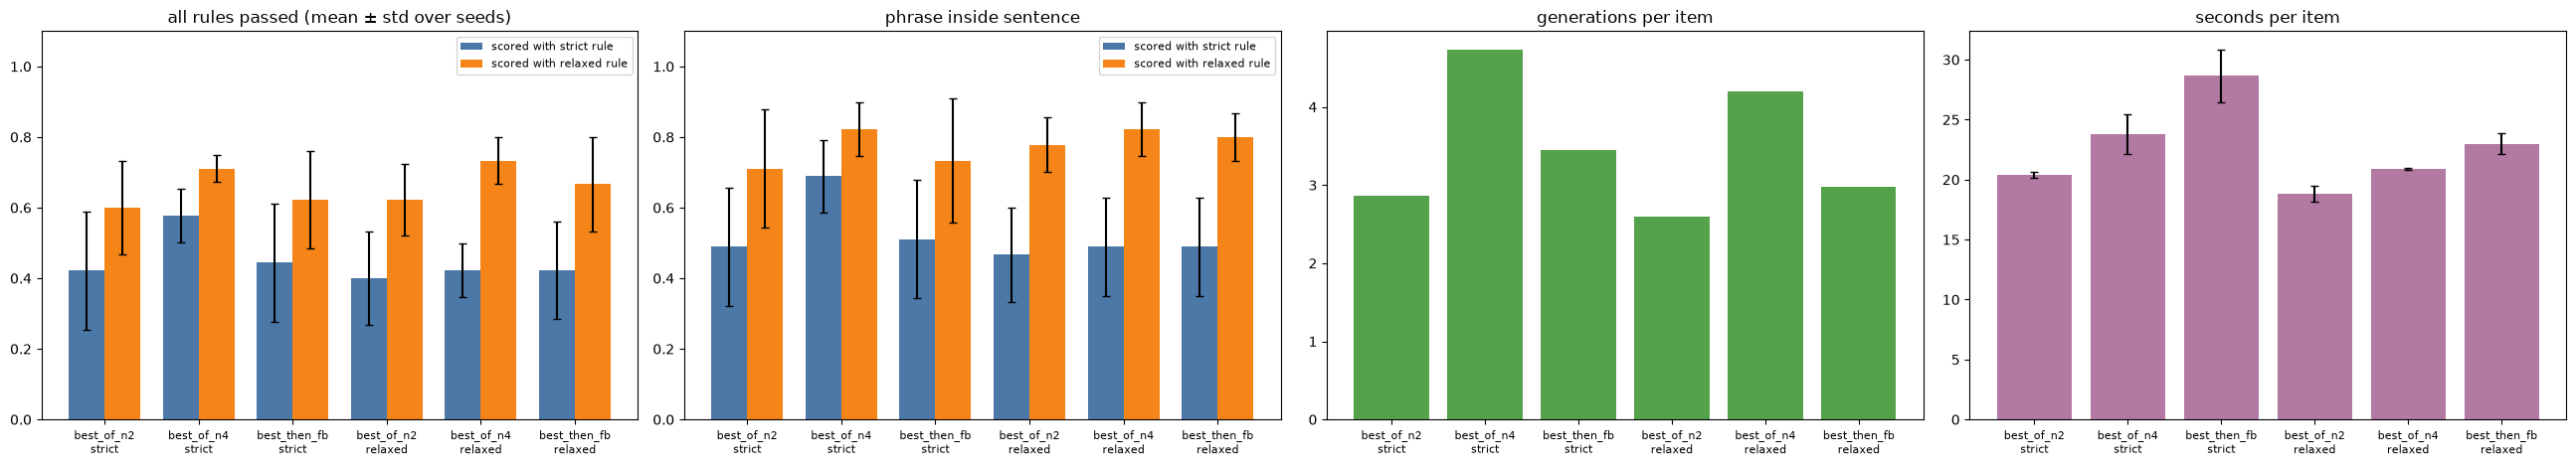

In [3]:
def score_relaxed(text, g):
    s = score_must(text, g, 'retry')
    d = parse_json(text)
    s['integrated'] = bool(d and isinstance(d.get('sns'), str) and integrated_relaxed(d['sns'], USER_POINTS[g]['must']))
    return s


frames = []
prev = pd.read_csv(REGEN_CSV, keep_default_na=False)
prev = prev[(prev.error == '') & (prev.method == 'best_of_n')].assign(method='best_of_n2|strict')
new = pd.read_csv(REGEN2_CSV, keep_default_na=False)
new = new[new.error == '']
for src in [prev, new]:
    frames.append(src.drop_duplicates(['method', 'seed', 'item'], keep='last'))
r2 = pd.concat(frames, ignore_index=True)
rows = []
for _, r in r2.iterrows():
    base = dict(method=r.method, seed=int(r.seed), item=r['item'], game=r.game, n_gen=int(r.n_gen), sec=float(r.sec_total),
                text=r.text)
    for score_rule, fn in [('strict', lambda t, g: score_must(t, g, 'retry')), ('relaxed', score_relaxed)]:
        rows.append(dict(base, score_rule=score_rule, **fn(r.text, r.game)))
r2s = pd.DataFrame(rows)
r2s['all_rules'] = r2s.format_ok & r2s.must_kept & r2s.integrated & (r2s.promo_violation == False) & (r2s.cliche == False)
R2_METHODS = ['best_of_n2|strict', 'best_of_n4|strict', 'best_then_fb|strict',
              'best_of_n2|relaxed', 'best_of_n4|relaxed', 'best_then_fb|relaxed']
per_seed2 = r2s.groupby(['score_rule', 'method', 'seed']).agg(
    format_ok=('format_ok', 'mean'), must_kept=('must_kept', 'mean'), integrated=('integrated', 'mean'),
    cliche=('cliche', 'mean'), all_rules=('all_rules', 'mean'), n_gen=('n_gen', 'mean'), sec=('sec', 'mean'))
summ2 = per_seed2.groupby(['score_rule', 'method']).agg(['mean', 'std'])
r2s.to_csv(OUT_DIR / 'regen2_scored.csv', index=False, encoding='utf-8-sig')
summ2.to_csv(OUT_DIR / 'regen2_summary.csv', encoding='utf-8-sig')
print('조합별 건수:', r2.groupby('method').size().to_dict())
display(summ2.round(3))
by_game = r2s.groupby(['score_rule', 'method', 'game']).all_rules.mean().unstack().round(3)
by_game.to_csv(OUT_DIR / 'regen2_by_game.csv', encoding='utf-8-sig')
print('게임별 규칙 전부 통과 (seed 평균)')
display(by_game)
if (OUT_DIR / 'regen2_runs.csv').exists():
    print('조합별 실행 기록 (regen2_runs.csv)')
    display(pd.read_csv(OUT_DIR / 'regen2_runs.csv', keep_default_na=False))

methods = [m for m in R2_METHODS if m in set(r2s.method)]
fig, axes = plt.subplots(1, 4, figsize=(26, 4.8))
x = np.arange(len(methods))
for k, (rule, color) in enumerate([('strict', '#4C78A8'), ('relaxed', '#F58518')]):
    s = summ2.loc[rule].reindex(methods)
    axes[0].bar(x + (k - 0.5) * 0.38, s[('all_rules', 'mean')], 0.38, yerr=s[('all_rules', 'std')].fillna(0), capsize=3,
                color=color, label=f'scored with {rule} rule')
    axes[1].bar(x + (k - 0.5) * 0.38, s[('integrated', 'mean')], 0.38, yerr=s[('integrated', 'std')].fillna(0), capsize=3,
                color=color, label=f'scored with {rule} rule')
s = summ2.loc['strict'].reindex(methods)
axes[2].bar(x, s[('n_gen', 'mean')], color='#54A24B')
axes[3].bar(x, s[('sec', 'mean')], yerr=s[('sec', 'std')].fillna(0), capsize=3, color='#B279A2')
for ax, title in zip(axes, ['all rules passed (mean ± std over seeds)', 'phrase inside sentence', 'generations per item',
                            'seconds per item']):
    ax.set_xticks(x, [m.replace('|', '\n') for m in methods], fontsize=8)
    ax.set_title(title)
for ax in axes[:2]:
    ax.set_ylim(0, 1.1)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / 'regen2_compare.png', dpi=90)
plt.show()

## 조합별 문구 예시 (seed 0)

In [4]:
pd.set_option('display.max_colwidth', 400)
for g in GAMES:
    f0 = [p.name for gg, p in SAMPLES if gg == g][0]
    print(g, f0, '| 꼭 넣을 문구:', USER_POINTS[g]['must'])
    ex = r2s[(r2s['item'] == f0) & (r2s.seed == 0)].pivot_table(index='method', columns='score_rule', values='all_rules',
                                                                 aggfunc='first')
    ex['text'] = r2s[(r2s['item'] == f0) & (r2s.seed == 0) & (r2s.score_rule == 'strict')].set_index('method').text
    display(ex.reindex(methods))
# 보고서용: 게임별 첫 이미지의 seed 0 문구를 조합별로 저장
ex_all = r2s[r2s['item'].isin([[p.name for gg, p in SAMPLES if gg == g][0] for g in GAMES]) & (r2s.seed == 0)]
ex_all.to_csv(OUT_DIR / 'regen2_examples.csv', index=False, encoding='utf-8-sig')

nai gen_0729_screenshot.png | 꼭 넣을 문구: 11월 업데이트 기념 30% 할인


score_rule,relaxed,strict,text
method,,,
best_of_n2|strict,True,True,"{""store"": [""검은 고양이 기사가 빨간 모자를 쓰고 돌담 위에 앉아 있는, 동화책 같은 손그림 스타일의 게임입니다."", ""11월 업데이트로 신규 동료가 추가되어 더 풍성한 모험을 기대할 수 있어요.""], ""sns"": ""빨간 모자와 녹색 망토를 걸친 고양이 기사가 돌담 위에 앉아 있는, 11월 업데이트 기념 30% 할인 중인 어드벤처 게임입니다.""}"
best_of_n4|strict,True,True,"{""store"": [""검은 고양이 기사가 빨간 모자를 쓰고 돌담 위에 앉아 있는, 동화책 같은 손그림 스타일의 게임입니다."", ""11월 업데이트로 신규 동료가 추가되어 더 풍성한 모험을 기대할 수 있어요.""], ""sns"": ""빨간 모자와 녹색 망토를 걸친 고양이 기사가 돌담 위에 앉아 있는, 11월 업데이트 기념 30% 할인 중인 어드벤처 게임입니다.""}"
best_then_fb|strict,True,True,"{""store"": [""검은 고양이 기사가 빨간 모자를 쓰고 돌담 위에 앉아 있는, 동화책 같은 손그림 스타일의 게임입니다."", ""11월 업데이트로 신규 동료가 추가되어 더 풍성한 모험을 기대할 수 있어요.""], ""sns"": ""빨간 모자와 녹색 망토를 걸친 고양이 기사가 돌담 위에 앉아 있는, 11월 업데이트 기념 30% 할인 중인 어드벤처 게임입니다.""}"
best_of_n2|relaxed,True,True,"{""store"": [""검은 고양이 기사가 빨간 모자를 쓰고 돌담 위에 앉아 있는, 동화책 같은 손그림 스타일의 게임입니다."", ""11월 업데이트로 신규 동료가 추가되어 더 풍성한 모험을 기대할 수 있어요.""], ""sns"": ""빨간 모자와 녹색 망토를 걸친 고양이 기사가 돌담 위에 앉아 있는, 11월 업데이트 기념 30% 할인 중인 어드벤처 게임입니다.""}"
best_of_n4|relaxed,True,True,"{""store"": [""검은 고양이 기사가 빨간 모자를 쓰고 돌담 위에 앉아 있는, 동화책 같은 손그림 스타일의 게임입니다."", ""11월 업데이트로 신규 동료가 추가되어 더 풍성한 모험을 기대할 수 있어요.""], ""sns"": ""빨간 모자와 녹색 망토를 걸친 고양이 기사가 돌담 위에 앉아 있는, 11월 업데이트 기념 30% 할인 중인 어드벤처 게임입니다.""}"
best_then_fb|relaxed,True,True,"{""store"": [""검은 고양이 기사가 빨간 모자를 쓰고 돌담 위에 앉아 있는, 동화책 같은 손그림 스타일의 게임입니다."", ""11월 업데이트로 신규 동료가 추가되어 더 풍성한 모험을 기대할 수 있어요.""], ""sns"": ""빨간 모자와 녹색 망토를 걸친 고양이 기사가 돌담 위에 앉아 있는, 11월 업데이트 기념 30% 할인 중인 어드벤처 게임입니다.""}"


x72 x72_scene_0497.png | 꼭 넣을 문구: 스팀 찜하기


score_rule,relaxed,strict,text
method,,,
best_of_n2|strict,True,False,"{""store"": [""16비트 픽셀 아트로 그려진 던전에서 4명이 함께 펼쳐지는 협동 모험, 스팀 찜하기"", ""보물상자와 금화를 찾아보며, 마법사와 기사가 맞서는 몬스터들과의 대결을 즐겨보세요.""], ""sns"": ""스팀 찜하기, 4명이 함께 펼쳐지는 픽셀 던전에서 금화와 보물상자를 찾아보세요!""}"
best_of_n4|strict,True,True,"{""store"": [""픽셀 아트 던전에서 4명이 함께 싸우고, 웃으며 보물 상자를 열어보세요."", ""스팀 찜하기로 친구들과 함께하는 모험을 준비하세요.""], ""sns"": ""스팀 찜하기로 4명이 함께 싸우고 웃는 던전 모험을 시작하세요.""}"
best_then_fb|strict,True,False,"{""store"": [""16비트 픽셀 아트로 그려진 던전에서 4명이 함께 펼쳐지는 협동 모험, 스팀 찜하기"", ""보물상자와 금화를 찾아보며, 마법사와 기사가 맞서는 몬스터들과의 대결을 즐겨보세요.""], ""sns"": ""스팀 찜하기, 4명이 함께 펼쳐지는 픽셀 던전에서 금화와 보물상자를 찾아보세요!""}"
best_of_n2|relaxed,True,False,"{""store"": [""16비트 픽셀 아트로 그려진 던전에서 4명이 함께 펼쳐지는 협동 모험, 스팀 찜하기"", ""보물상자와 금화를 찾아보며, 마법사와 기사가 맞서는 몬스터들과의 대결을 즐겨보세요.""], ""sns"": ""스팀 찜하기, 4명이 함께 펼쳐지는 픽셀 던전에서 금화와 보물상자를 찾아보세요!""}"
best_of_n4|relaxed,True,False,"{""store"": [""16비트 픽셀 아트로 그려진 던전에서 4명이 함께 펼쳐지는 협동 모험, 스팀 찜하기"", ""보물상자와 금화를 찾아보며, 마법사와 기사가 맞서는 몬스터들과의 대결을 즐겨보세요.""], ""sns"": ""스팀 찜하기, 4명이 함께 펼쳐지는 픽셀 던전에서 금화와 보물상자를 찾아보세요!""}"
best_then_fb|relaxed,True,False,"{""store"": [""16비트 픽셀 아트로 그려진 던전에서 4명이 함께 펼쳐지는 협동 모험, 스팀 찜하기"", ""보물상자와 금화를 찾아보며, 마법사와 기사가 맞서는 몬스터들과의 대결을 즐겨보세요.""], ""sns"": ""스팀 찜하기, 4명이 함께 펼쳐지는 픽셀 던전에서 금화와 보물상자를 찾아보세요!""}"


kaykit kk_0223.png | 꼭 넣을 문구: 신규 영웅 로그 추가


score_rule,relaxed,strict,text
method,,,
best_of_n2|strict,True,True,"{""store"": [""로우폴리 스타일의 판타지 어드벤처, 푸른 모자와 지팡이를 들고 전투를 시작하세요."", ""신규 영웅 로그 추가로 더 풍부한 전략과 즐거움을 경험해 보세요.""], ""sns"": ""신규 영웅 로그 추가로, 푸른 모자와 지팡이로 마법의 전투를 펼쳐보세요!""}"
best_of_n4|strict,True,True,"{""store"": [""로우폴리 영웅이 펄럭이는 마법사의 지팡이, 신규 영웅 로그 추가로 더 풍부한 전투가 시작됩니다."", ""한손·양손 무기와 지팡이로 즐기는 판타지 어드벤처, 회피와 연속 공격으로 매 순간을 끌어내세요.""], ""sns"": ""파란색 모자와 녹색 눈을 가진 마법사가 지팡이를 휘두르는 모습, 신규 영웅 로그 추가로 더 흥미로운 전투를 경험해보세요.""}"
best_then_fb|strict,True,True,"{""store"": [""로우폴리 스타일의 판타지 어드벤처, 푸른 모자와 지팡이를 들고 전투를 시작하세요."", ""신규 영웅 로그 추가로 더 풍부한 전략과 즐거움을 경험해 보세요.""], ""sns"": ""신규 영웅 로그 추가로, 푸른 모자와 지팡이로 마법의 전투를 펼쳐보세요!""}"
best_of_n2|relaxed,True,True,"{""store"": [""로우폴리 스타일의 판타지 어드벤처, 푸른 모자와 지팡이를 들고 전투를 시작하세요."", ""신규 영웅 로그 추가로 더 풍부한 전략과 즐거움을 경험해 보세요.""], ""sns"": ""신규 영웅 로그 추가로, 푸른 모자와 지팡이로 마법의 전투를 펼쳐보세요!""}"
best_of_n4|relaxed,True,True,"{""store"": [""로우폴리 영웅이 펄럭이는 마법사의 지팡이, 신규 영웅 로그 추가로 더 풍부한 전투가 시작됩니다."", ""한손·양손 무기와 지팡이로 즐기는 판타지 어드벤처, 회피와 연속 공격으로 매 순간을 끌어내세요.""], ""sns"": ""파란색 모자와 녹색 눈을 가진 마법사가 지팡이를 휘두르는 모습, 신규 영웅 로그 추가로 더 흥미로운 전투를 경험해보세요.""}"
best_then_fb|relaxed,True,True,"{""store"": [""로우폴리 스타일의 판타지 어드벤처, 푸른 모자와 지팡이를 들고 전투를 시작하세요."", ""신규 영웅 로그 추가로 더 풍부한 전략과 즐거움을 경험해 보세요.""], ""sns"": ""신규 영웅 로그 추가로, 푸른 모자와 지팡이로 마법의 전투를 펼쳐보세요!""}"
